In [1]:
import pandas as pd

# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
extended_df = pd.read_csv(file_path, index_col=0)


In [2]:
display(extended_df.head())
display(extended_df.describe())

,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date,needed_personal,sby_used_percent,personal_calculated_by_calls,...,month,day_of_week,day_of_month,week_of_year,day_of_year,is_weekend,is_holiday,tavg,tmin,tmax
date,,,,,,,,,,,,,,,,,,,,,
2016-04-01,73,8154.0,1700,90,4.0,0.0,1459468800,1704.0,0.044444,1734.893617,...,4,4,1,13,92,False,False,8.3,5.0,13.1
2016-04-02,64,8526.0,1700,90,70.0,0.0,1459555200,1770.0,0.777778,1814.042553,...,4,5,2,13,93,True,False,9.9,1.3,16.4
2016-04-03,68,8088.0,1700,90,0.0,0.0,1459641600,1700.0,0.000000,1720.851064,...,4,6,3,13,94,True,False,13.1,6.1,19.1
2016-04-04,71,7044.0,1700,90,0.0,0.0,1459728000,1700.0,0.000000,1498.723404,...,4,0,4,14,95,False,False,15.2,9.5,20.6
2016-04-05,63,7236.0,1700,90,0.0,0.0,1459814400,1700.0,0.000000,1539.574468,...,4,1,5,14,96,False,False,16.0,8.4,22.7


,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date,needed_personal,sby_used_percent,personal_calculated_by_calls,...,call_stress,year,month,day_of_week,day_of_month,week_of_year,day_of_year,tavg,tmin,tmax
count,1152.000000,1152.000000,1152.000000,1152.0,1152.000000,1152.000000,1.152000e+03,1152.000000,1152.000000,1152.000000,...,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000
mean,68.808160,7919.531250,1833.333333,90.0,30.182292,16.335938,1.509192e+09,1863.515625,0.335359,1685.006649,...,4.238179,2017.333333,6.424479,3.002604,15.674479,26.023438,180.072049,11.268229,7.051997,15.467882
std,14.293942,1290.063571,97.759435,0.0,71.753595,53.394089,2.874511e+07,124.273086,0.797262,274.481611,...,0.541139,0.977594,3.394101,2.002386,8.778030,14.770423,103.880984,7.711124,6.679351,9.095201
min,36.000000,4074.000000,1700.000000,90.0,0.000000,0.000000,1.459469e+09,1700.000000,0.000000,866.808511,...,2.263333,2016.000000,1.000000,0.000000,1.000000,1.000000,1.000000,-8.800000,-12.800000,-5.800000
25%,58.000000,6978.000000,1800.000000,90.0,0.000000,0.000000,1.484330e+09,1800.000000,0.000000,1484.680851,...,3.860882,2017.000000,4.000000,1.000000,8.000000,14.000000,95.000000,5.200000,1.900000,7.900000
50%,68.000000,7932.000000,1800.000000,90.0,0.000000,0.000000,1.509192e+09,1874.500000,0.000000,1687.659574,...,4.323158,2017.000000,6.000000,3.000000,16.000000,25.000000,174.000000,10.600000,6.700000,14.950000
75%,78.000000,8827.500000,1900.000000,90.0,0.000000,0.000000,1.534054e+09,1905.250000,0.000000,1878.191489,...,4.765372,2018.000000,9.000000,5.000000,23.000000,39.000000,270.000000,17.800000,12.400000,23.000000
max,119.000000,11850.000000,2000.000000,90.0,461.000000,465.000000,1.558915e+09,2455.000000,5.122222,2521.276596,...,4.896288,2019.000000,12.000000,6.000000,31.000000,52.000000,366.000000,28.900000,23.900000,38.000000


In [3]:
def calculate_custom_personal_metrics(df: pd.DataFrame, orig_column : str , pred_column : str, print_results: bool = False) -> dict:

    df = df.copy(deep=True)

    # Berechnung der Unterbesetzung und Überbesetzung
    df['understaffed'] = df[orig_column] > df[pred_column]
    df['overstaffed'] = df[orig_column] < df[pred_column]
    df['perfect'] = df[orig_column] == df[pred_column]
    
    # Anteil an Tagen mit Unterbesetzung
    total_days = len(df)
    understaffed_days = df['understaffed'].sum()
    overstaffed_days = df['overstaffed'].sum()
    perfect_days = df['perfect'].sum()
    
    # Durchschnittliche Über- und Unterbesetzung
    avg_understaffing = (df[orig_column] - df[pred_column])[df['understaffed']].mean()
    avg_overstaffing = (df[pred_column] - df[orig_column])[df['overstaffed']].mean()
    median_understaffing = (df[orig_column] - df[pred_column])[df['understaffed']].median()
    median_overstaffing = (df[pred_column] - df[orig_column])[df['overstaffed']].median()

    results = {
        'Anteil an Tagen mit Unterbesetzung (%)': understaffed_days / total_days * 100,
        'Anteil an Tagen mit Überbesetzung (%)': overstaffed_days / total_days * 100,
        'Anteil an Tagen mit perfekter Prediction (%)': perfect_days / total_days * 100,
        'Durchschnittliche Überbesetzung': avg_overstaffing,
        'Durchschnittliche Unterbesetzung': avg_understaffing,
        'Median Überbesetzung': median_overstaffing,
        'Median Unterbesetzung': median_understaffing
    }

    if print_results:
        print(f'Results: - ' + ', '.join(f'{key}: {value}' for key, value in results.items()))

    return results

display("Aktueller Stand der Metriken mit festem n_sby:")
display(calculate_custom_personal_metrics(extended_df, "sby_need", "n_sby", print_results=False))

display("Stand, wenn man dynamisch aus Calls berechnet:")
display(calculate_custom_personal_metrics(extended_df, "sby_need", "sby_need_calculated_by_calls", print_results=False))

'Aktueller Stand der Metriken mit festem n_sby:'

{'Anteil an Tagen mit Unterbesetzung (%)': 13.10763888888889,
 'Anteil an Tagen mit Überbesetzung (%)': 86.63194444444444,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.26041666666666663,
 'Durchschnittliche Überbesetzung': 84.44689378757515,
 'Durchschnittliche Unterbesetzung': 101.7748344370861,
 'Median Überbesetzung': 90.0,
 'Median Unterbesetzung': 85.0}

'Stand, wenn man dynamisch aus Calls berechnet:'

{'Anteil an Tagen mit Unterbesetzung (%)': 0.08680555555555555,
 'Anteil an Tagen mit Überbesetzung (%)': 30.46875,
 'Anteil an Tagen mit perfekter Prediction (%)': 69.44444444444444,
 'Durchschnittliche Überbesetzung': 46.2178577923258,
 'Durchschnittliche Unterbesetzung': 0.1276595744682254,
 'Median Überbesetzung': 50.085106382978694,
 'Median Unterbesetzung': 0.1276595744682254}

# Baseline Model

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

target_column_name = "sby_need"

train_size = int(len(extended_df) * 0.8)
train, test = extended_df.iloc[:train_size], extended_df.iloc[train_size:]

# Baseline-Modell: Durchschnitt der Zielvariable im Trainingsset
baseline_pred = train[target_column_name].mean()

test = test.copy()

test['baseline_pred'] = baseline_pred


$R^2=-0.00$
$MAE=48.46$
$RMSE=75.87$


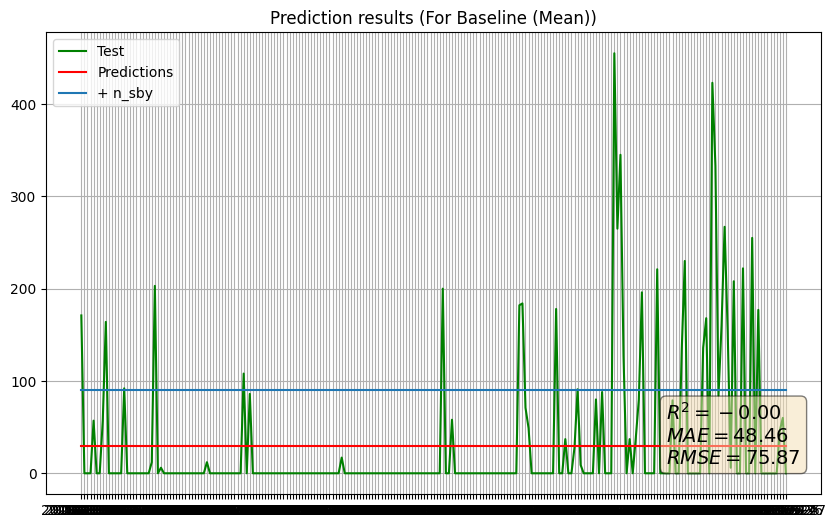

{'Anteil an Tagen mit Unterbesetzung (%)': 19.480519480519483,
 'Anteil an Tagen mit Überbesetzung (%)': 80.51948051948052,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.0,
 'Durchschnittliche Überbesetzung': 29.51070015060768,
 'Durchschnittliche Unterbesetzung': 126.7832066594281,
 'Median Überbesetzung': 29.99457111834962,
 'Median Unterbesetzung': 124.00542888165037}

In [5]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, root_mean_squared_error
import matplotlib.pyplot as plt

def plot_regression_predictions(y_true: pd.DataFrame, y_pred: pd.DataFrame, y_train: pd.DataFrame = None, annotation : str = "", additional_column_df : pd.DataFrame = None) -> None:
    
    # Metrics
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)

    mape = mean_absolute_percentage_error(y_true, y_pred)

    # Plot 
    plt.figure(figsize=(10, 6))
    plt.title(f'Prediction results' + (f" ({annotation})" if annotation else ""))

    if y_train is not None:
        plt.plot(y_train.index, y_train, label='Train', color='blue')

    plt.plot(y_true.index, y_true, label='Test', color='green')
    plt.plot(y_true.index, y_pred, label='Predictions', color='red')

    if additional_column_df is not None:

        max_value = max([
        y_true.select_dtypes(include=[float, int]).max().max(),
        y_pred.select_dtypes(include=[float, int]).max().max(),
        additional_column_df.select_dtypes(include=[float, int]).max().max(),
        ])

        for column in additional_column_df.columns:
            if additional_column_df[column].dtype == bool:
                plt.plot(additional_column_df.index, additional_column_df[column].astype(int) * max_value, label =  "+ " +column + " (bool)", linestyle="dotted")
            else:
                plt.plot(additional_column_df.index, additional_column_df[column], label = "+ " + column)

    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)

    textstr = '\n'.join((
        r'$R^2=%.2f$' % (r2, ),
        r'$MAE=%.2f$' % (mae, ),
        r'$RMSE=%.2f$' % (rmse, )))

    print(textstr)

    plt.text(0.8, 0.2, textstr, transform=plt.gca().transAxes, fontsize=14,
        verticalalignment='top', bbox=props)

    plt.legend()
    plt.grid()
    plt.show()


plot_regression_predictions(test[[target_column_name]], test[["baseline_pred"]],  additional_column_df=test[["n_sby"]], annotation="For Baseline (Mean)")

display(calculate_custom_personal_metrics(test, "sby_need", "baseline_pred"))

# Time series analysis

In [6]:
regularization_for_underestimation = 50

target_column_name = "calls"
exogenous_features = ["day_of_week", "day_of_month", "day_of_year"]
#exogenous_features = []

## GRU (Gated Recurrent Unit)

In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import GRU, Dense, Bidirectional, Dropout
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * regularization_for_underestimation,
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

data = extended_df[[target_column_name] + exogenous_features]

# Indizes speichern
indices = data.index

# Daten normalisieren
scaler_x = StandardScaler()
scaler_y = StandardScaler()

# Exogene Features und Zielspalte trennen und separat skalieren
scaled_x = scaler_x.fit_transform(data[exogenous_features])  # Exogene Features skalieren
scaled_y = scaler_y.fit_transform(data[[target_column_name]])  # Zielwert (calls) skalieren

# Sequenzen erstellen
def create_sequences(data_x, data_y, seq_length):
    xs, ys = [], []
    for i in range(len(data_x) - seq_length):
        x = data_x[i:i+seq_length]
        y = data_y[i+seq_length]  # Zielwert ist um `seq_length` verschoben
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30  # Anzahl der Tage in einer Sequenz
X, y = create_sequences(scaled_x, scaled_y, seq_length)

# Daten in Trainings- und Testsets aufteilen
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# GRU-Modell erstellen
model = Sequential()
model.add(Bidirectional(GRU(units=128, return_sequences=True, input_shape=(seq_length, X_train.shape[2]))))
model.add(Dropout(0.3))
model.add(Bidirectional(GRU(units=128)))
model.add(Dropout(0.3))
model.add(Dense(1))

# Modell kompilieren
model.compile(optimizer=Adam(learning_rate=0.001), loss=custom_loss)

# Early Stopping Callback
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.2, callbacks=[early_stopping])

# Plotten des Trainingsverlaufs
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainings loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Modell loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Vorhersagen machen
predictions = model.predict(X_test)

# Denormalisieren der Vorhersagen
predictions = scaler_y.inverse_transform(predictions)  # Denormalisieren der Vorhersagen
y_test = scaler_y.inverse_transform(y_test)  # Denormalisieren der Test-Zielwerte

# Indizes wieder hinzufügen
y_test_df = pd.DataFrame(y_test, index=indices[-len(y_test):], columns=['True'])
predictions_df = pd.DataFrame(predictions, index=indices[-len(predictions):], columns=['Predicted'])

# R2-Score berechnen
r2 = r2_score(y_test, predictions)
print(f'R2-Score: {r2}')

# Vorhersagen und tatsächliche Werte anzeigen
combined_df = pd.concat([y_test_df, predictions_df], axis=1)
print(combined_df)


2024-09-09 16:29:18.936449: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2024-09-09 16:29:18.939048: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2024-09-09 16:29:18.947596: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-09-09 16:29:18.962749: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-09-09 16:29:18.967094: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-09-09 16:29:18.977896: I tensorflow/core/platform/cpu_feature_gu

Epoch 1/100


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


KeyboardInterrupt: 

$R^2=-0.54$
$MAE=1252.73$
$RMSE=1615.46$


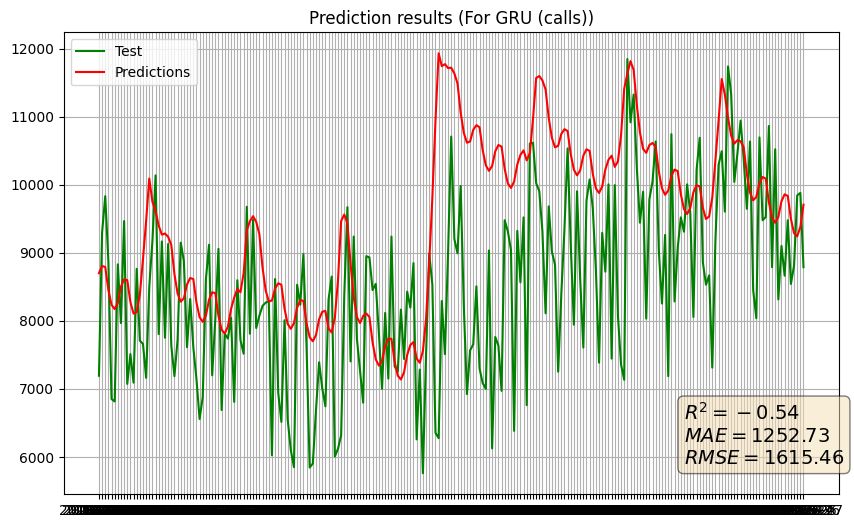

$R^2=-3.75$
$MAE=107.05$
$RMSE=165.98$


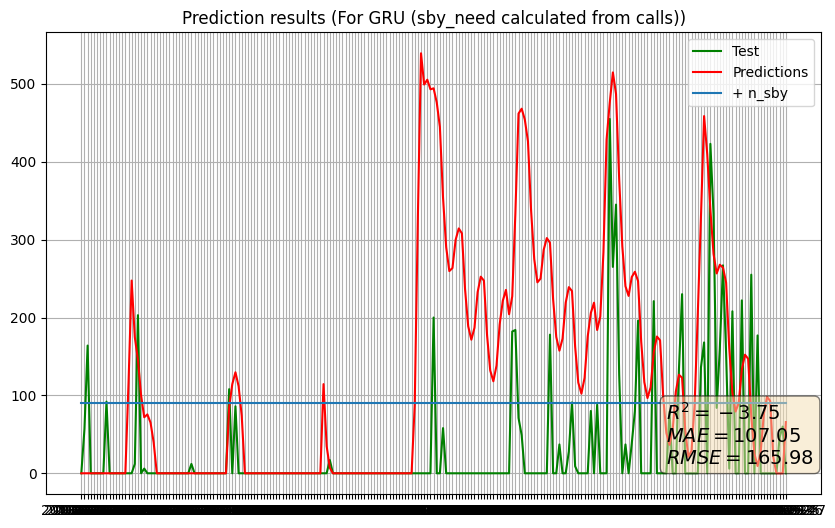

{'Anteil an Tagen mit Unterbesetzung (%)': 8.88888888888889,
 'Anteil an Tagen mit Überbesetzung (%)': 52.888888888888886,
 'Anteil an Tagen mit perfekter Prediction (%)': 38.22222222222222,
 'Durchschnittliche Überbesetzung': 190.43624389582948,
 'Durchschnittliche Unterbesetzung': 71.23738364361705,
 'Median Überbesetzung': 172.6391705452129,
 'Median Unterbesetzung': 58.66703374335111}

In [ ]:

result_df = extended_df.loc[y_test_df.index, ["n_duty", "sby_need", "n_sby", "needed_personal", "calls"]]

# Values below 0 will be set 0
predictions[predictions < 0] = 0

if target_column_name == "sby_need":

    result_df["sby_need_calc"] = predictions
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
    plot_regression_predictions(y_test, predictions, additional_column_df=result_df[["n_sby"]], annotation="For GRU")

if target_column_name == "calls":
    result_df["predicted_calls"] = predictions
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.7) - row.n_duty) , axis=1)

    plot_regression_predictions(result_df[["calls"]], result_df[["predicted_calls"]], annotation="For GRU (calls)")

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For GRU (sby_need calculated from calls)")
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

if target_column_name == "needed_personal":
    result_df["predicted_needed_personal"] = predictions

    display(calculate_custom_personal_metrics(result_df, "needed_personal", "predicted_needed_personal"))

    plot_regression_predictions(y_test, predictions, annotation="For GRU (needed_personal)")



In [ ]:
from keras.models import load_model
import joblib

# Modell speichern
model.save('../../app/models/gru_model.keras')  # Speichern des Modells im HDF5-Format

joblib.dump(scaler_x, '../../app/models/scaler_x.pkl')
joblib.dump(scaler_y, '../../app/models/scaler_y.pkl')

['../../app/models/scaler_y.pkl']

In [ ]:
import numpy as np
import pandas as pd
import joblib
from keras.models import load_model
import tensorflow as tf
from datetime import datetime

# Definiere erneut die benutzerdefinierte Verlustfunktion
def custom_loss(y_true, y_pred):
    regularization_for_underestimation = 50  # Passe dies an, wenn nötig
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * regularization_for_underestimation,
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# Funktion zur Extraktion der exogenen Features aus einem Datum (ohne 'timestamp')
def extract_features(date):
    day_of_week = date.weekday()  # 0=Montag, 6=Sonntag
    day_of_month = date.day
    day_of_year = date.timetuple().tm_yday
    return [day_of_week, day_of_month, day_of_year]

# Funktion zur Vorhersage neuer Daten
def predict_new_data(model_path, scaler_x_path, scaler_y_path, seq_length, days):
    """
    model_path: Pfad zum gespeicherten GRU-Modell (z.B. 'gru_model.keras')
    scaler_x_path: Pfad zum gespeicherten Scaler für die exogenen Features (z.B. 'scaler_x.pkl')
    scaler_y_path: Pfad zum gespeicherten Scaler für die Zielspalte (z.B. 'scaler_y.pkl')
    seq_length: Länge der Sequenz, die das Modell erwartet (z.B. 30)
    days: Liste von Datumseinträgen im Format YYYY-MM-DD (als Strings)

    Rückgabe: Dictionary {Tag: Vorhersage}
    """
    # Modell und Scaler laden
    model = load_model(model_path, custom_objects={'custom_loss': custom_loss})
    scaler_x = joblib.load(scaler_x_path)  # Scaler für die exogenen Features laden
    scaler_y = joblib.load(scaler_y_path)  # Scaler für die Zielspalte laden
    
    # Features für die Tage extrahieren (ohne 'timestamp')
    new_data = pd.DataFrame([extract_features(pd.to_datetime(day)) for day in days],
                            columns=["day_of_week", "day_of_month", "day_of_year"],
                            index=days)
    
    # Daten normalisieren (nur exogene Features)
    scaled_data = scaler_x.transform(new_data)

    # Erstelle Sequenzen für die Vorhersage
    def create_sequences(data, seq_length):
        xs = []
        for i in range(len(data) - seq_length + 1):
            x = data[i:i + seq_length]
            xs.append(x)
        return np.array(xs)

    # Erstelle Sequenzen aus den neuen Daten (die Sequenzlänge beachten)
    X_new = create_sequences(scaled_data, seq_length)

    # Vorhersagen machen
    predictions = model.predict(X_new)

    # Denormalisieren der Vorhersagen (verwende scaler_y für den Zielwert)
    predictions_denorm = scaler_y.inverse_transform(predictions)  # Denormalisieren der Vorhersagen

    # Erstelle ein Dictionary {day: prediction}
    result = {}
    for i, day in enumerate(days[seq_length - 1:]):  # Beachte: Sequenzen starten erst nach seq_length Tagen
        result[day] = predictions_denorm[i][0]  # Nur den ersten Wert der Vorhersage verwenden

    return result

# Beispiel für die Nutzung der Funktion
model_path = '../../app/models/gru_model.keras'
scaler_x_path = '../../app/models/scaler_x.pkl'
scaler_y_path = '../../app/models/scaler_y.pkl'
seq_length = 30

# Liste der Tage (als Strings im Format YYYY-MM-DD)
days_to_predict = list(result_df.head(30).index)

# Vorhersagen für die Tage
predictions = predict_new_data(model_path, scaler_x_path, scaler_y_path, seq_length, days_to_predict)

# Vorhersagen anzeigen
print(predictions)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 442ms/step
{'2018-11-13': 8615.151}


In [ ]:
result_df.head(30)

,n_duty,sby_need,n_sby,needed_personal,calls,predicted_calls,sby_need_calc
date,,,,,,,
2018-10-15,1900,0.0,90,1900.0,7194.0,8702.165039,0.000000
2018-10-16,1900,57.0,90,1957.0,9300.0,8807.085938,0.000000
2018-10-17,1900,164.0,90,2064.0,9834.0,8793.538086,0.000000
2018-10-18,1900,0.0,90,1900.0,8874.0,8451.677734,0.000000
2018-10-19,1900,0.0,90,1900.0,6852.0,8236.967773,0.000000
2018-10-20,1900,0.0,90,1900.0,6816.0,8173.609863,0.000000
2018-10-21,1900,0.0,90,1900.0,8832.0,8267.738281,0.000000
2018-10-22,1900,0.0,90,1900.0,7968.0,8504.545898,0.000000
2018-10-23,1900,92.0,90,1992.0,9468.0,8612.208984,0.000000


In [ ]:
stop

NameError: name 'stop' is not defined

## LSTM (Long Short-Term Memory)

Epoch 1/20


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - loss: 2.9422 - val_loss: 0.5177
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.1331 - val_loss: 0.0659
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0984 - val_loss: 0.0582
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0802 - val_loss: 0.0577
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0755 - val_loss: 0.0578
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0675 - val_loss: 0.0612
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0742 - val_loss: 0.0540
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0684 - val_loss: 0.0641
Epoch 9/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0700 - val_loss: 0.0702
Epoch 10/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0621 - val_loss: 0.0637
Epoch 11/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0635 - val_loss: 0.0599
Epoch 12/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0663 - val_l

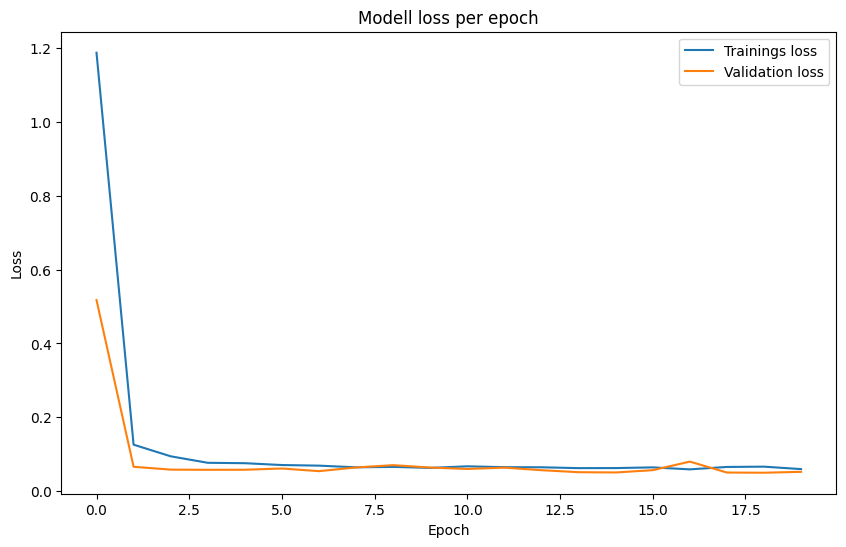

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import LSTM, Dense, Bidirectional, Dropout
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.optimizers import Adam

# Daten mit Ziel- und exogenen Features
data = extended_df[[target_column_name] + exogenous_features]

# Indizes speichern
indices = data.index

# Daten normalisieren
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Sequenzen erstellen
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length, 0]  # Zielwert ist die erste Spalte
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30  # Anzahl der Tage in einer Sequenz
X, y = create_sequences(scaled_data, seq_length)

# Daten in Trainings- und Testsets aufteilen
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# LSTM-Modell erstellen
model = Sequential()

# V1 LSTM
#model.add(LSTM(units=50, return_sequences=True, input_shape=(seq_length, X_train.shape[2])))
#model.add(LSTM(units=50))

# V2 LSTM
model.add(Bidirectional(LSTM(units=100, return_sequences=True, input_shape=(seq_length, X_train.shape[2]))))
model.add(Dropout(0.2))
model.add(Bidirectional(LSTM(units=100)))
model.add(Dropout(0.2))
######

model.add(Dense(1))

# V1 Modell kompilieren
#model.compile(optimizer='adam', loss='mean_squared_error')

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * regularization_for_underestimation,  # Straffaktor für Unterschätzungen
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# V2 Modell kompilieren
# model.compile(optimizer='adam', loss=custom_loss)

# V3 Modell kompilieren
model.compile(optimizer=Adam(learning_rate=0.001), loss=custom_loss)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainings loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Modell loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Vorhersagen machen
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(np.concatenate((predictions, np.zeros((predictions.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

y_test = scaler.inverse_transform(np.concatenate((y_test.reshape(-1, 1), np.zeros((y_test.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]
y_train = scaler.inverse_transform(np.concatenate((y_train.reshape(-1, 1), np.zeros((y_train.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions = pd.DataFrame(predictions, index=indices[-len(predictions):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])


$R^2=-0.57$
$MAE=1310.53$
$RMSE=1632.73$


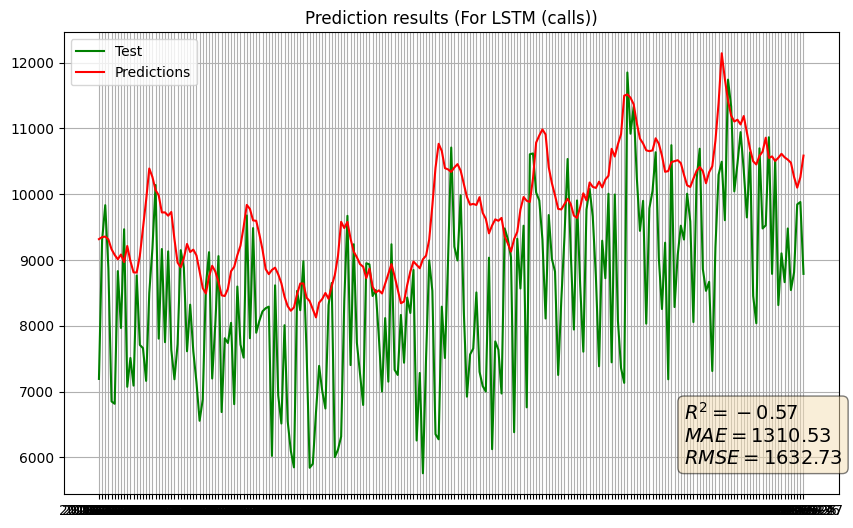

$R^2=-1.45$
$MAE=76.35$
$RMSE=119.17$


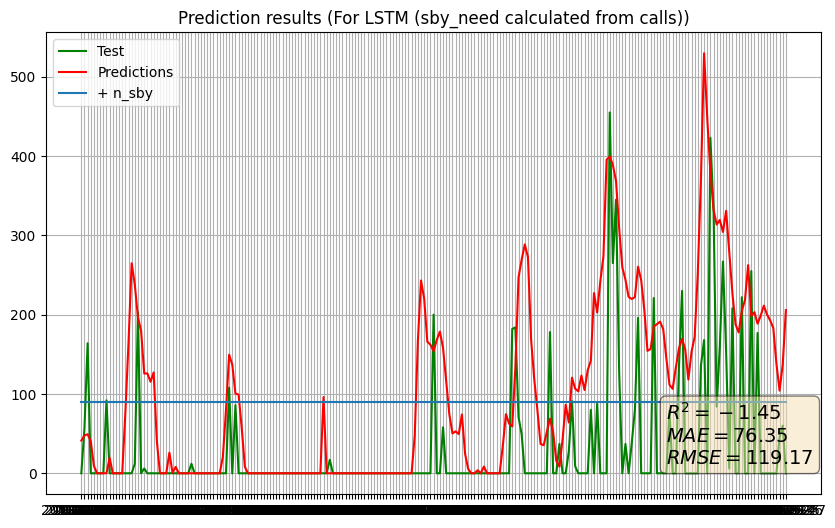

{'Anteil an Tagen mit Unterbesetzung (%)': 8.0,
 'Anteil an Tagen mit Überbesetzung (%)': 55.55555555555556,
 'Anteil an Tagen mit perfekter Prediction (%)': 36.44444444444444,
 'Durchschnittliche Überbesetzung': 130.40226284408533,
 'Durchschnittliche Unterbesetzung': 48.79407187302942,
 'Median Überbesetzung': 123.84139299392655,
 'Median Unterbesetzung': 44.5363285541539}

In [ ]:
result_df = extended_df.loc[y_test.index, ["n_duty", "sby_need", "n_sby", "needed_personal"]]


# Values below 0 will be set 0
predictions[predictions < 0] = 0

if target_column_name == "sby_need":
    result_df["sby_need_calc"] = predictions
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
    plot_regression_predictions(y_test, predictions, additional_column_df=result_df[["n_sby"]], annotation="For LSTM")

if target_column_name == "calls":
    result_df["predicted_calls"] = predictions
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(y_test, predictions, annotation="For LSTM (calls)")

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For LSTM (sby_need calculated from calls)")
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

if target_column_name == "needed_personal":
    result_df["predicted_needed_personal"] = predictions

    display(calculate_custom_personal_metrics(result_df, "needed_personal", "predicted_needed_personal"))

    plot_regression_predictions(y_test, predictions, annotation="For LSTM (needed_personal)")


## CNN (Convolutional Neural Networks)

Epoch 1/20


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 4.8696 - val_loss: 0.7040
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3381 - val_loss: 0.1092
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1948 - val_loss: 0.1526
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1938 - val_loss: 0.1311
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1430 - val_loss: 0.1000
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1299 - val_loss: 0.0956
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1312 - val_loss: 0.1026
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1521 - val_loss: 0.0891
Epoch 9/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1351 - val_loss: 0.0984
Epoch 10/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1201 - val_loss: 0.0875
Epoch 11/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1265 - val_loss: 0.0929
Epoch 12/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1266 - val_loss: 0.0857


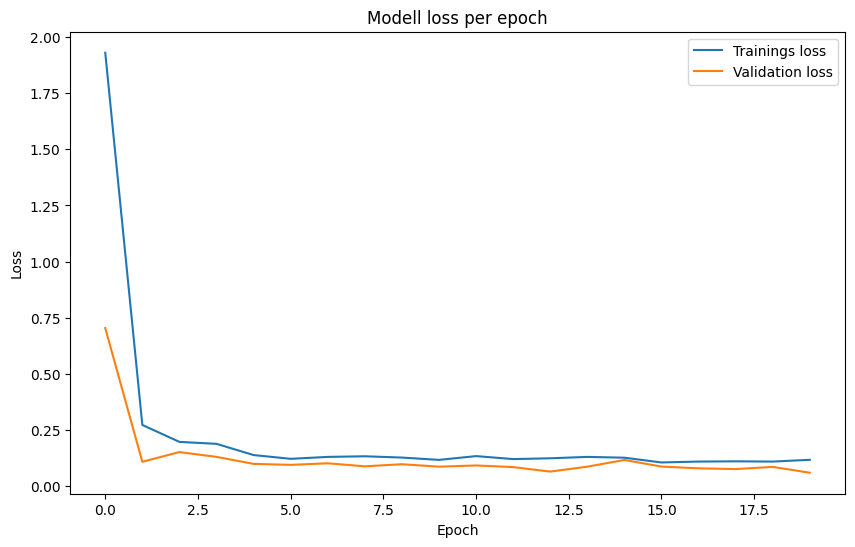

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import Conv1D, Dense, Flatten, Dropout, MaxPooling1D
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.optimizers import Adam

# Daten mit Ziel- und exogenen Features
data = extended_df[[target_column_name] + exogenous_features]

# Indizes speichern
indices = data.index

# Daten normalisieren
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Sequenzen erstellen
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length, 0]  # Zielwert ist die erste Spalte
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30  # Anzahl der Tage in einer Sequenz
X, y = create_sequences(scaled_data, seq_length)

# Daten in Trainings- und Testsets aufteilen
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# CNN-Modell erstellen
model = Sequential()
model.add(Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(seq_length, X_train.shape[2])))
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.2))
model.add(Flatten())
model.add(Dense(50, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(1))

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * regularization_for_underestimation,  # Straffaktor für Unterschätzungen
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# Modell kompilieren
model.compile(optimizer=Adam(learning_rate=0.001), loss=custom_loss)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainings loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Modell loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Vorhersagen machen
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(np.concatenate((predictions, np.zeros((predictions.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

y_test = scaler.inverse_transform(np.concatenate((y_test.reshape(-1, 1), np.zeros((y_test.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]
y_train = scaler.inverse_transform(np.concatenate((y_train.reshape(-1, 1), np.zeros((y_train.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions = pd.DataFrame(predictions, index=indices[-len(predictions):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])



$R^2=-1.40$
$MAE=1742.17$
$RMSE=2020.26$


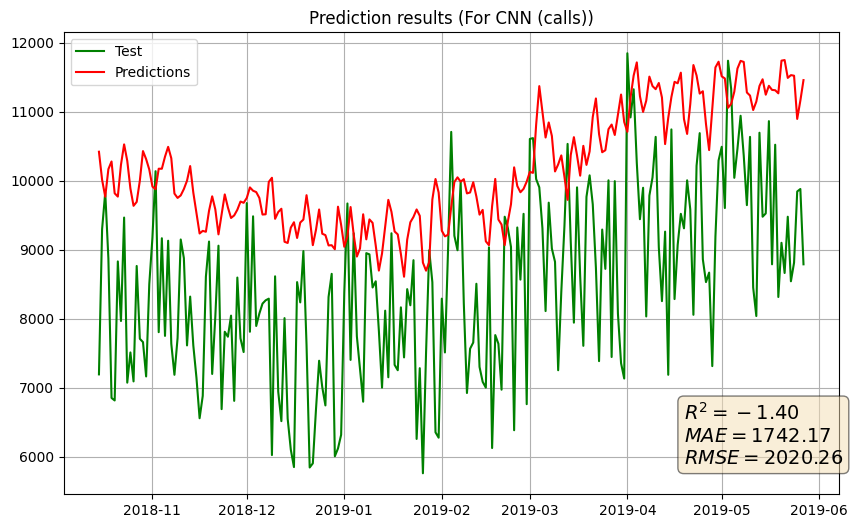

$R^2=-5.21$
$MAE=143.80$
$RMSE=189.75$


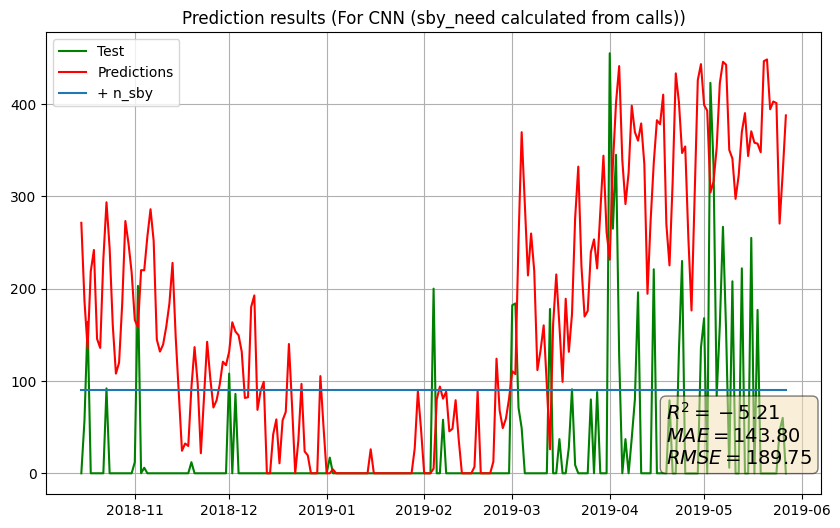

{'Anteil an Tagen mit Unterbesetzung (%)': 4.444444444444445,
 'Anteil an Tagen mit Überbesetzung (%)': 76.88888888888889,
 'Anteil an Tagen mit perfekter Prediction (%)': 18.666666666666668,
 'Durchschnittliche Überbesetzung': 181.56218354136922,
 'Durchschnittliche Unterbesetzung': 94.49063279628788,
 'Median Überbesetzung': 159.43406820297196,
 'Median Unterbesetzung': 74.0072278976445}

In [ ]:
result_df = extended_df.loc[y_test.index, ["n_duty", "sby_need", "n_sby", "needed_personal"]]

# Values below 0 will be set 0
predictions[predictions < 0] = 0

if target_column_name == "sby_need":
    result_df["sby_need_calc"] = predictions
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
    plot_regression_predictions(y_test, predictions, additional_column_df=result_df[["n_sby"]], annotation="For CNN")

if target_column_name == "calls":
    result_df["predicted_calls"] = predictions
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(y_test, predictions, annotation="For CNN (calls)")

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For CNN (sby_need calculated from calls)")
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))


In [ ]:
stop_it_here

NameError: name 'stop_it_here' is not defined

## TDNN (Time Delay Neural Network)

Epoch 1/20


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 5.0421 - val_loss: 1.3560
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4629 - val_loss: 0.1333
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1994 - val_loss: 0.2268
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2942 - val_loss: 0.1825
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1819 - val_loss: 0.1884
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1994 - val_loss: 0.1630
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1645 - val_loss: 0.1536
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1399 - val_loss: 0.1415
Epoch 9/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1413 - val_loss: 0.1424
Epoch 10/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1483 - val_loss: 0.1590
Epoch 11/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1351 - val_loss: 0.1398
Epoch 12/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1502 - val_loss: 0.0695


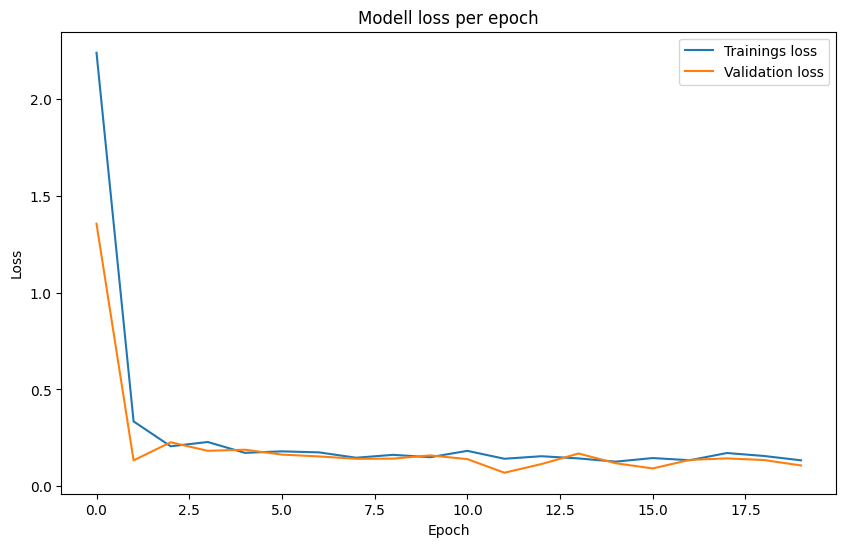

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import Conv1D, Dense, Flatten, Dropout
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.optimizers import Adam

# Daten mit Ziel- und exogenen Features
data = extended_df[[target_column_name] + exogenous_features]

# Indizes speichern
indices = data.index

# Daten normalisieren
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Sequenzen erstellen
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length, 0]  # Zielwert ist die erste Spalte
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30  # Anzahl der Tage in einer Sequenz
X, y = create_sequences(scaled_data, seq_length)

# Daten in Trainings- und Testsets aufteilen
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# TDNN-Modell erstellen
model = Sequential()
model.add(Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(seq_length, X_train.shape[2])))
model.add(Dropout(0.2))
model.add(Flatten())
model.add(Dense(50, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(1))

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * regularization_for_underestimation,  # Straffaktor für Unterschätzungen
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# Modell kompilieren
model.compile(optimizer=Adam(learning_rate=0.001), loss=custom_loss)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainings loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Modell loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Vorhersagen machen
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(np.concatenate((predictions, np.zeros((predictions.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

y_test = scaler.inverse_transform(np.concatenate((y_test.reshape(-1, 1), np.zeros((y_test.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]
y_train = scaler.inverse_transform(np.concatenate((y_train.reshape(-1, 1), np.zeros((y_train.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions = pd.DataFrame(predictions, index=indices[-len(predictions):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])


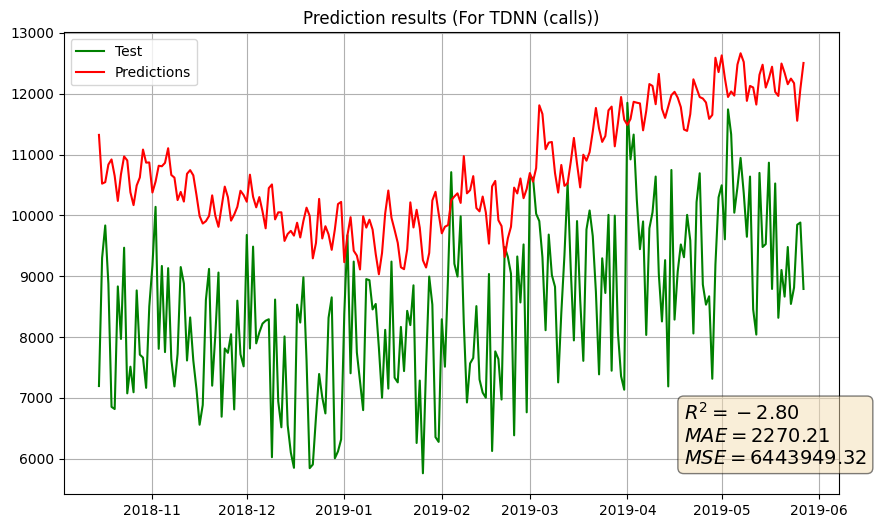

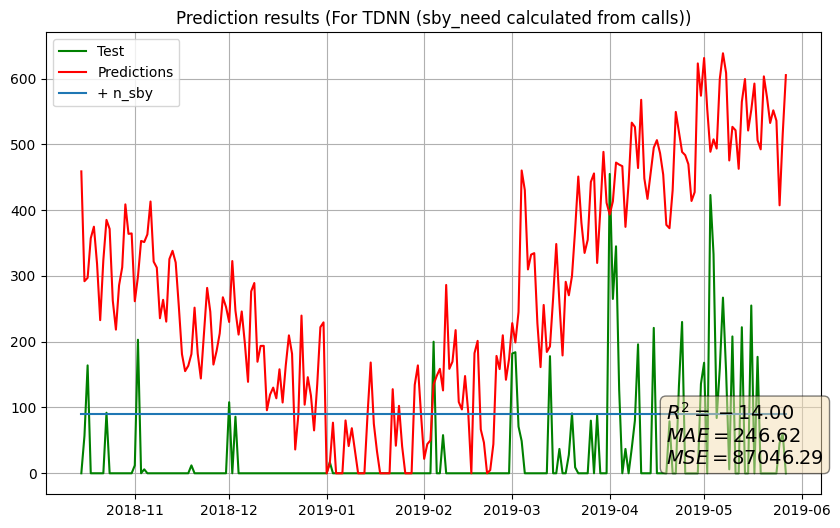

{'Anteil an Tagen mit Unterbesetzung (%)': 1.3333333333333335,
 'Anteil an Tagen mit Überbesetzung (%)': 91.55555555555556,
 'Anteil an Tagen mit perfekter Prediction (%)': 7.111111111111111,
 'Durchschnittliche Überbesetzung': 268.74358836308227,
 'Durchschnittliche Unterbesetzung': 42.9673852920536,
 'Median Überbesetzung': 250.63949012756302,
 'Median Unterbesetzung': 61.802710294723965}

In [ ]:

result_df = extended_df.loc[y_test.index, ["n_duty", "sby_need", "n_sby", "needed_personal"]]

# Values below 0 will be set 0
predictions[predictions < 0] = 0

if target_column_name == "sby_need":
    result_df["sby_need_calc"] = predictions
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
    plot_regression_predictions(y_test, predictions, additional_column_df=result_df[["n_sby"]], annotation="For TDNN")

if target_column_name == "calls":
    result_df["predicted_calls"] = predictions
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(y_test, predictions, annotation="For TDNN (calls)")

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For TDNN (sby_need calculated from calls)")
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))


## RNN (Recurrent neural network)

Epoch 1/20


23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 6.7389 - val_loss: 1.2285
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.4677 - val_loss: 1.2531
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.2037 - val_loss: 0.6353
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.9400 - val_loss: 0.3114
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.0227 - val_loss: 0.4939
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.0285 - val_loss: 0.9150
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9277 - val_loss: 0.3445
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.8544 - val_loss: 0.2429
Epoch 9/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6507 - val_loss: 0.3392
Epoch 10/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5432 - val_loss: 0.4246
Epoch 11/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5291 - val_loss: 0.1234
Epoch 12/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5136 - val_loss: 0.2044

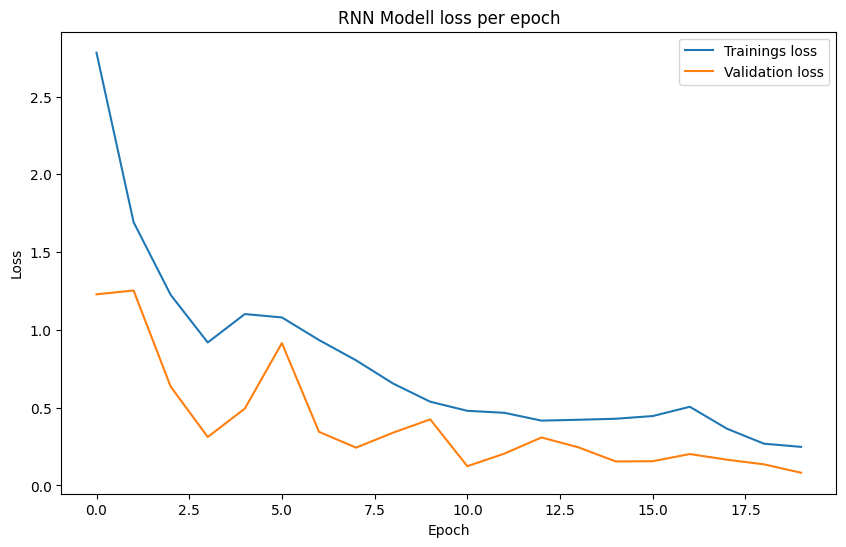

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import SimpleRNN, Dense, Dropout
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.optimizers import Adam

# Daten mit Ziel- und exogenen Features
data = extended_df[[target_column_name] + exogenous_features]

# Indizes speichern
indices = data.index

# Daten normalisieren
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Sequenzen erstellen
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length, 0]  # Zielwert ist die erste Spalte
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30  # Anzahl der Tage in einer Sequenz
X, y = create_sequences(scaled_data, seq_length)

# Daten in Trainings- und Testsets aufteilen
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# RNN-Modell erstellen
model = Sequential()

model.add(SimpleRNN(units=100, return_sequences=True, input_shape=(seq_length, X_train.shape[2])))
model.add(Dropout(0.2))
model.add(SimpleRNN(units=100))
model.add(Dropout(0.2))

model.add(Dense(1))

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * regularization_for_underestimation,  # Straffaktor für Unterschätzungen
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# Modell kompilieren
model.compile(optimizer=Adam(learning_rate=0.001), loss=custom_loss)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainings loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('RNN Modell loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Vorhersagen machen
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(np.concatenate((predictions, np.zeros((predictions.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

y_test = scaler.inverse_transform(np.concatenate((y_test.reshape(-1, 1), np.zeros((y_test.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]
y_train = scaler.inverse_transform(np.concatenate((y_train.reshape(-1, 1), np.zeros((y_train.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions = pd.DataFrame(predictions, index=indices[-len(predictions):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])


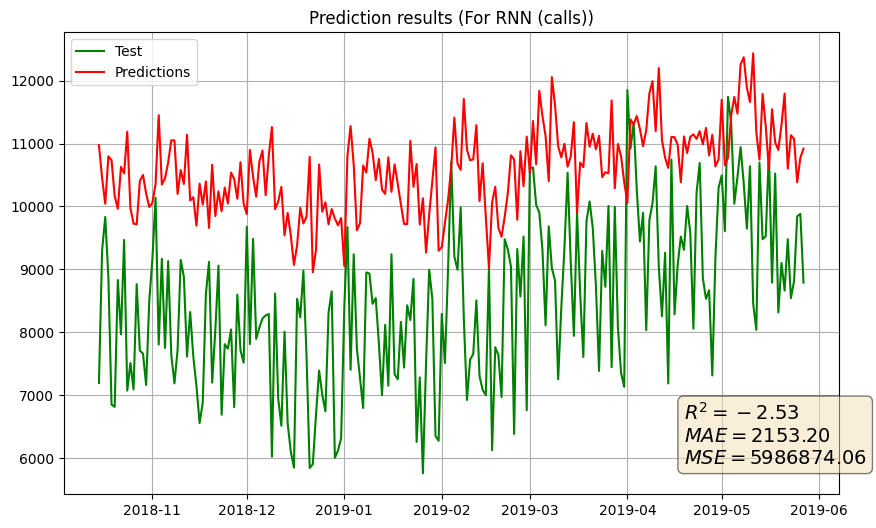

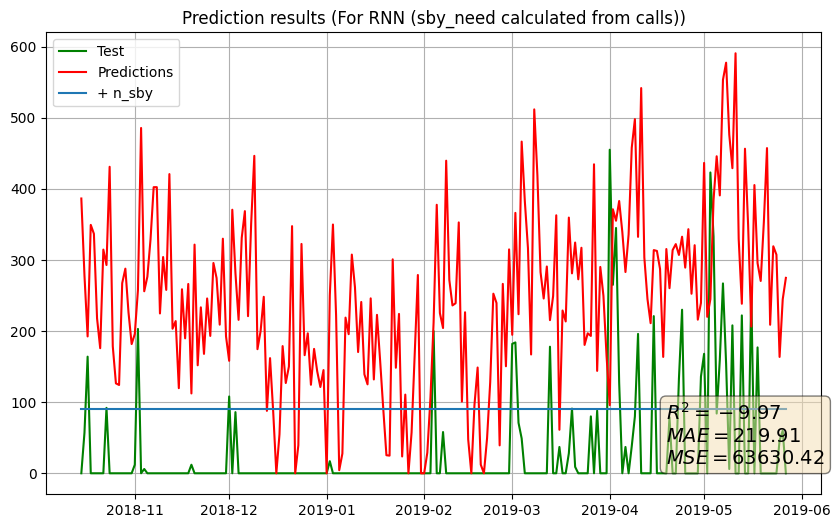

{'Anteil an Tagen mit Unterbesetzung (%)': 1.3333333333333335,
 'Anteil an Tagen mit Überbesetzung (%)': 95.11111111111111,
 'Anteil an Tagen mit perfekter Prediction (%)': 3.5555555555555554,
 'Durchschnittliche Überbesetzung': 228.47959319453332,
 'Durchschnittliche Unterbesetzung': 195.34726754824365,
 'Median Überbesetzung': 224.4354104995723,
 'Median Unterbesetzung': 178.15715003013656}

In [ ]:
result_df = extended_df.loc[y_test.index, ["n_duty", "sby_need", "n_sby", "needed_personal"]]

# Values below 0 will be set 0
predictions[predictions < 0] = 0

if target_column_name == "sby_need":
    result_df["sby_need_calc"] = predictions
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
    plot_regression_predictions(y_test, predictions, additional_column_df=result_df[["n_sby"]], annotation="For RNN")

if target_column_name == "calls":
    result_df["predicted_calls"] = predictions
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(y_test, predictions, annotation="For RNN (calls)")

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For RNN (sby_need calculated from calls)")
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))


## TCN (Temporal Convolutional Network)

Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - loss: 49.9168 - val_loss: 2.3646
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 4.4878 - val_loss: 1.8447
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2.3870 - val_loss: 3.0688
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2.1883 - val_loss: 0.3356
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.7874 - val_loss: 0.2201
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.7255 - val_loss: 0.1493
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.1815 - val_loss: 0.0836
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.4748 - val_loss: 0.0790
Epoch 9/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.5086 - val_loss: 0.1066
Epoch 10/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.9775 - val_loss: 0.1254
Epoch 11/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.9812 - val_loss: 0.0738
Epoch 12/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.

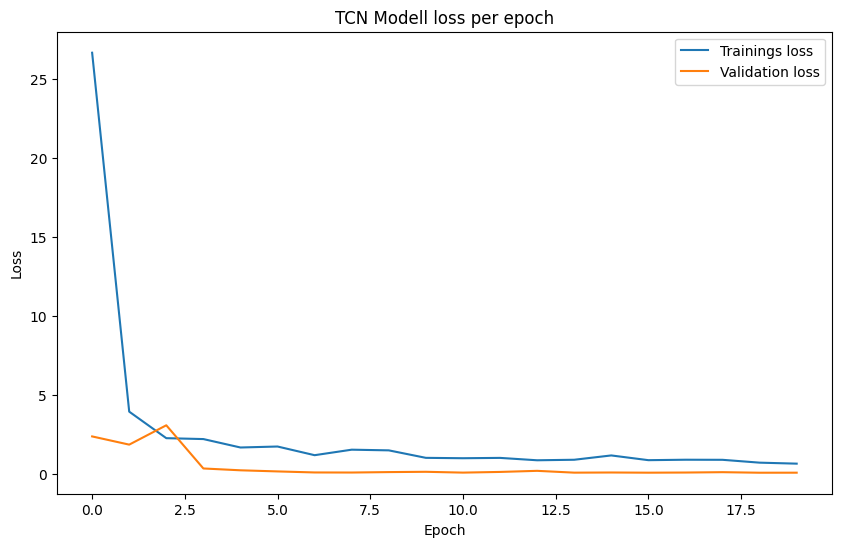

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import Conv1D, Dense, Dropout, BatchNormalization, Activation, SpatialDropout1D, Lambda, Add, GlobalAveragePooling1D
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.optimizers import Adam

# Daten mit Ziel- und exogenen Features
data = extended_df[[target_column_name] + exogenous_features]

# Indizes speichern
indices = data.index

# Daten normalisieren
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Sequenzen erstellen
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length, 0]  # Zielwert ist die erste Spalte
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30  # Anzahl der Tage in einer Sequenz
X, y = create_sequences(scaled_data, seq_length)

# Daten in Trainings- und Testsets aufteilen
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Residual Block für TCN
def residual_block(x, dilation_rate):
    prev_x = x
    for k in range(2):
        x = Conv1D(filters=64, kernel_size=2, padding='causal', dilation_rate=dilation_rate)(x)
        x = BatchNormalization()(x)
        x = Activation('relu')(x)
        x = SpatialDropout1D(0.2)(x)
    prev_x = Conv1D(filters=64, kernel_size=1, padding='same')(prev_x)
    x = Add()([prev_x, x])
    return x

# TCN-Modell erstellen
input_layer = tf.keras.layers.Input(shape=(seq_length, X_train.shape[2]))
x = input_layer
for dilation_rate in [1, 2, 4, 8, 16]:
    x = residual_block(x, dilation_rate)
x = GlobalAveragePooling1D()(x)
output_layer = Dense(1)(x)

model_tcn = tf.keras.models.Model(inputs=input_layer, outputs=output_layer)

# Asymmetrische Verlustfunktion definieren
def custom_loss(y_true, y_pred):
    loss = tf.where(tf.greater(y_true, y_pred), 
                    tf.square(y_true - y_pred) * regularization_for_underestimation,  # Straffaktor für Unterschätzungen
                    tf.square(y_true - y_pred))
    return tf.reduce_mean(loss)

# Modell kompilieren
model_tcn.compile(optimizer=Adam(learning_rate=0.001), loss=custom_loss)

# Modell trainieren
history_tcn = model_tcn.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

plt.figure(figsize=(10, 6))
plt.plot(history_tcn.history['loss'], label='Trainings loss')
plt.plot(history_tcn.history['val_loss'], label='Validation loss')
plt.title('TCN Modell loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Vorhersagen machen
predictions_tcn = model_tcn.predict(X_test)
predictions_tcn = scaler.inverse_transform(np.concatenate((predictions_tcn, np.zeros((predictions_tcn.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

y_test = scaler.inverse_transform(np.concatenate((y_test.reshape(-1, 1), np.zeros((y_test.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]
y_train = scaler.inverse_transform(np.concatenate((y_train.reshape(-1, 1), np.zeros((y_train.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions_tcn = pd.DataFrame(predictions_tcn, index=indices[-len(predictions_tcn):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])


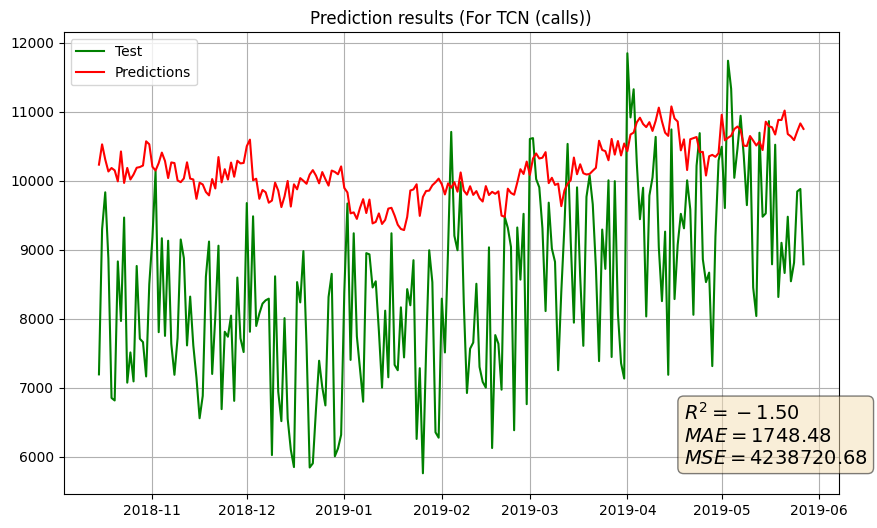

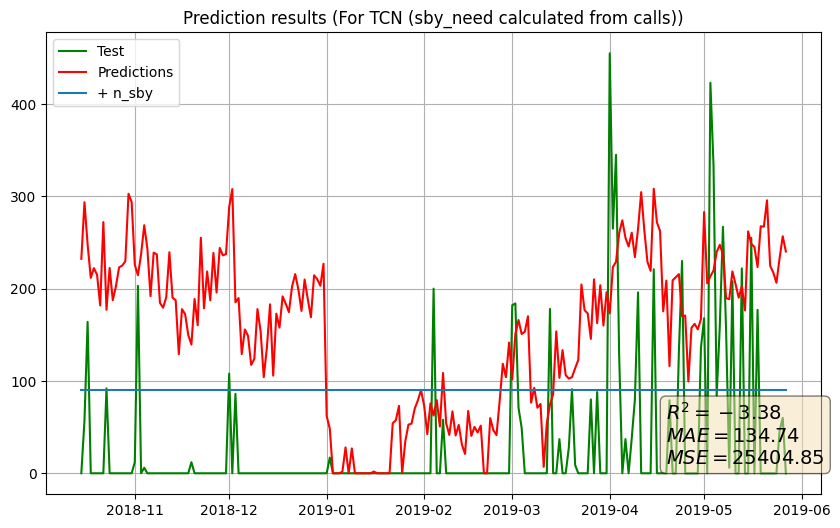

{'Anteil an Tagen mit Unterbesetzung (%)': 5.777777777777778,
 'Anteil an Tagen mit Überbesetzung (%)': 86.22222222222223,
 'Anteil an Tagen mit perfekter Prediction (%)': 8.0,
 'Durchschnittliche Überbesetzung': 149.91989882705096,
 'Durchschnittliche Unterbesetzung': 94.81132775086668,
 'Median Überbesetzung': 169.53885853290512,
 'Median Unterbesetzung': 80.431013822556}

In [ ]:
result_df = extended_df.loc[y_test.index, ["n_duty", "sby_need", "n_sby", "needed_personal"]]

# Values below 0 will be set 0
predictions[predictions < 0] = 0

if target_column_name == "sby_need":
    result_df["sby_need_calc"] = predictions_tcn
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
    plot_regression_predictions(y_test, predictions_tcn, additional_column_df=result_df[["n_sby"]], annotation="For TCN")

if target_column_name == "calls":
    result_df["predicted_calls"] = predictions_tcn
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.8) - row.n_duty) , axis=1)

    plot_regression_predictions(y_test, predictions_tcn, annotation="For TCN (calls)")

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For TCN (sby_need calculated from calls)")
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))


## Prophet

Importing plotly failed. Interactive plots will not work.


14:56:05 - cmdstanpy - INFO - Chain [1] start processing
14:56:05 - cmdstanpy - INFO - Chain [1] done processing
14:56:06 - cmdstanpy - INFO - Chain [1] start processing
14:56:06 - cmdstanpy - INFO - Chain [1] done processing
14:56:06 - cmdstanpy - INFO - Chain [1] start processing
14:56:06 - cmdstanpy - INFO - Chain [1] done processing
14:56:06 - cmdstanpy - INFO - Chain [1] start processing
14:56:06 - cmdstanpy - INFO - Chain [1] done processing
14:56:06 - cmdstanpy - INFO - Chain [1] start processing
14:56:06 - cmdstanpy - INFO - Chain [1] done processing


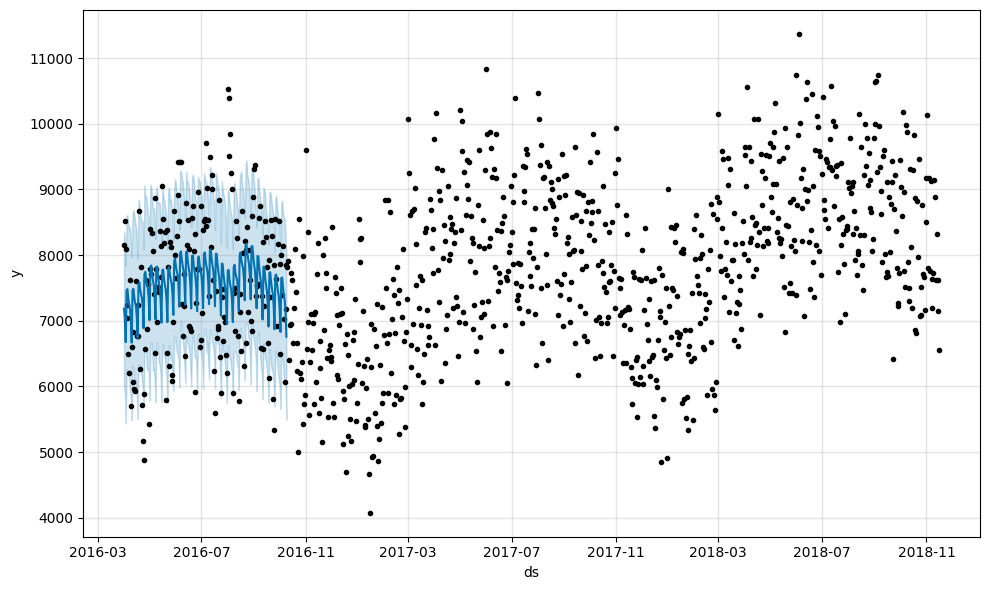

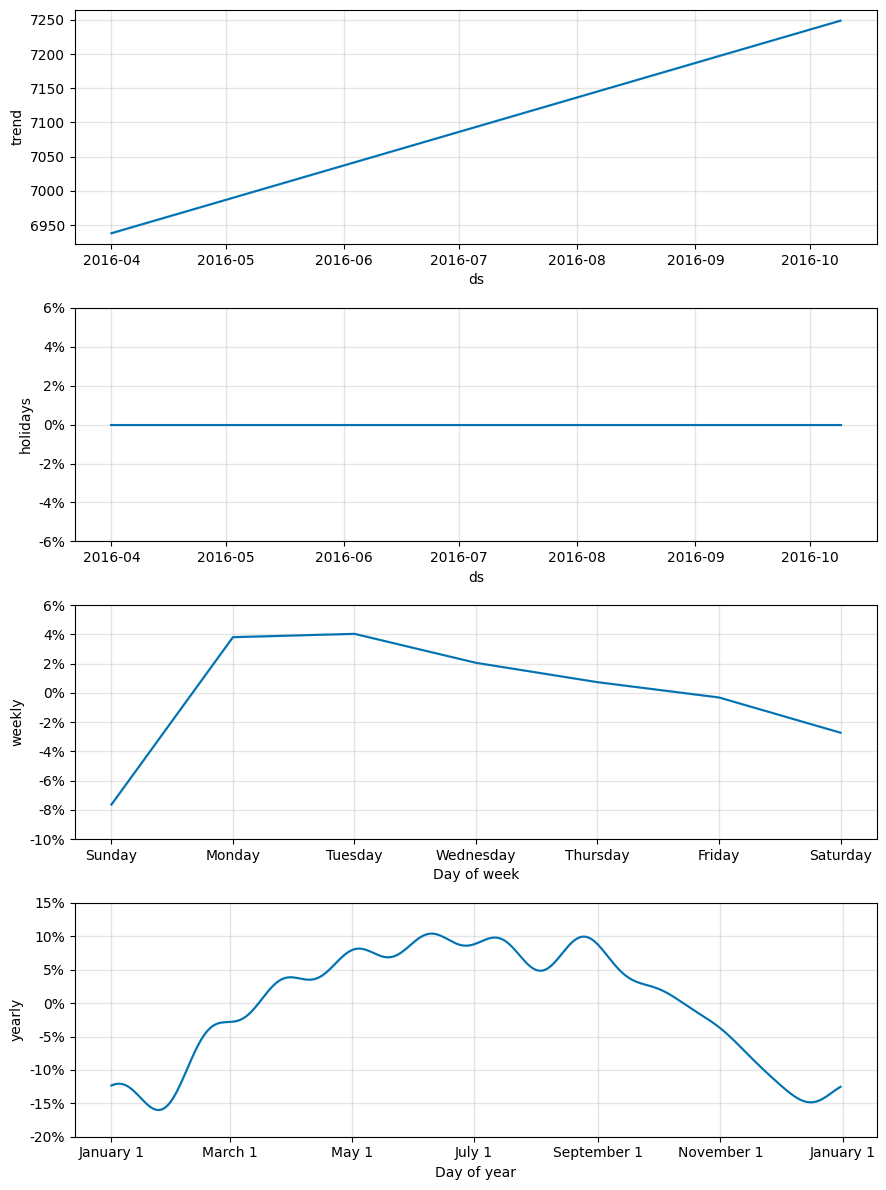

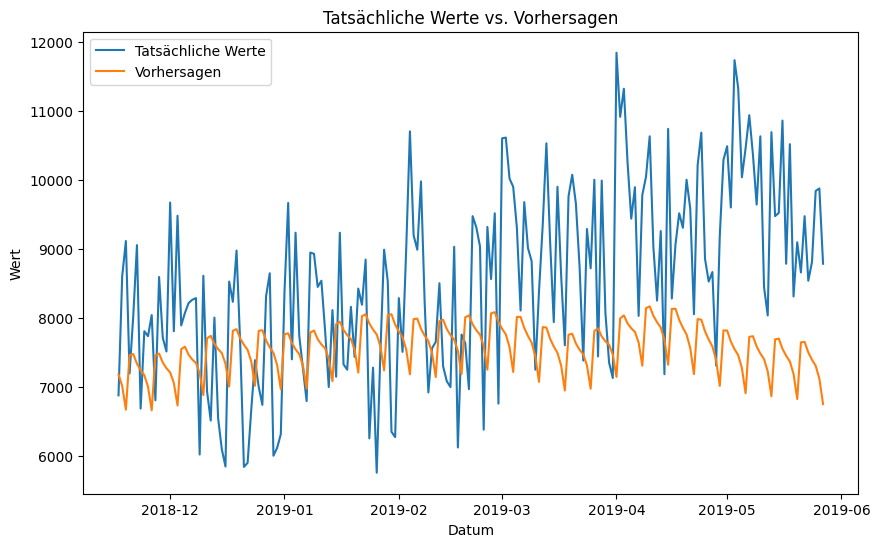

Durchschnittlicher MAE: 1179.85972107624
Durchschnittlicher MSE: 2105337.961293689
Durchschnittlicher R2-Score: -0.6393986188247235


In [ ]:
import pandas as pd
import numpy as np
from prophet import Prophet
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

# Daten vorbereiten
target_column_name = "calls"
exogenous_features = []  # Liste der exogenen Features

# Daten mit Ziel- und exogenen Features
data = extended_df[[target_column_name] + exogenous_features]

# Prophet erwartet eine Spalte 'ds' für das Datum und 'y' für den Zielwert
data = data.rename(columns={target_column_name: 'y'})
data['ds'] = data.index

# Feiertage definieren
from prophet.make_holidays import make_holidays_df

# Feiertage für Berlin erstellen
holidays = make_holidays_df(year_list=[2024], country='DE', state='BE')

# Cross-Validation Setup
tscv = TimeSeriesSplit(n_splits=5)
mae_scores = []
mse_scores = []
r2_scores = []

for train_index, test_index in tscv.split(data):
    train_data = data.iloc[train_index]
    test_data = data.iloc[test_index]

    # Prophet-Modell erstellen und anpassen
    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
        seasonality_mode='multiplicative',
        changepoint_prior_scale=0.1,  # Hyperparameter-Tuning
        seasonality_prior_scale=1.0,  # Hyperparameter-Tuning
        holidays=holidays
    )

    # Exogene Features hinzufügen
    for feature in exogenous_features:
        model.add_regressor(feature)

    # Modell trainieren
    model.fit(train_data)

    # Zukunftsdatenrahmen erstellen
    future = model.make_future_dataframe(periods=len(test_data))
    future = future.iloc[:len(test_data)]  # Index anpassen
    for feature in exogenous_features:
        future[feature] = test_data[feature].values  # Exogene Features für die Zukunft hinzufügen

    # Vorhersagen machen
    forecast = model.predict(future)

    # Metriken berechnen
    y_true = np.array(test_data['y'].values)
    y_pred = np.array(forecast['yhat'].values)

    mae_scores.append(mean_absolute_error(y_true, y_pred))
    mse_scores.append(mean_squared_error(y_true, y_pred))
    r2_scores.append(r2_score(y_true, y_pred))

# Letztes Modell für Plotting verwenden
fig1 = model.plot(forecast)
plt.show()

fig2 = model.plot_components(forecast)
plt.show()

# Vorhersagen und tatsächliche Werte plotten
plt.figure(figsize=(10, 6))
plt.plot(test_data['ds'], y_true, label='Tatsächliche Werte')
plt.plot(test_data['ds'], y_pred, label='Vorhersagen')
plt.xlabel('Datum')
plt.ylabel('Wert')
plt.title('Tatsächliche Werte vs. Vorhersagen')
plt.legend()
plt.show()

# Durchschnittliche Metriken berechnen
mae = np.mean(mae_scores)
mse = np.mean(mse_scores)
r2 = np.mean(r2_scores)

print(f"Durchschnittlicher MAE: {mae}")
print(f"Durchschnittlicher MSE: {mse}")
print(f"Durchschnittlicher R2-Score: {r2}")


# Experimental

Epoch 1/100


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 9s 77ms/step - loss: 0.0543 - val_loss: 0.0159
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.0210 - val_loss: 0.0204
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0174 - val_loss: 0.0139
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.0177 - val_loss: 0.0138
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0173 - val_loss: 0.0133
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0216 - val_loss: 0.0235
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0200 - val_loss: 0.0173
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0184 - val_loss: 0.0132
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.0165 - val_loss: 0.0231
Epoch 10/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0173 - val_loss: 0.0138
Epoch 11/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0159 - val_loss: 0.0193
Epoch 12/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0

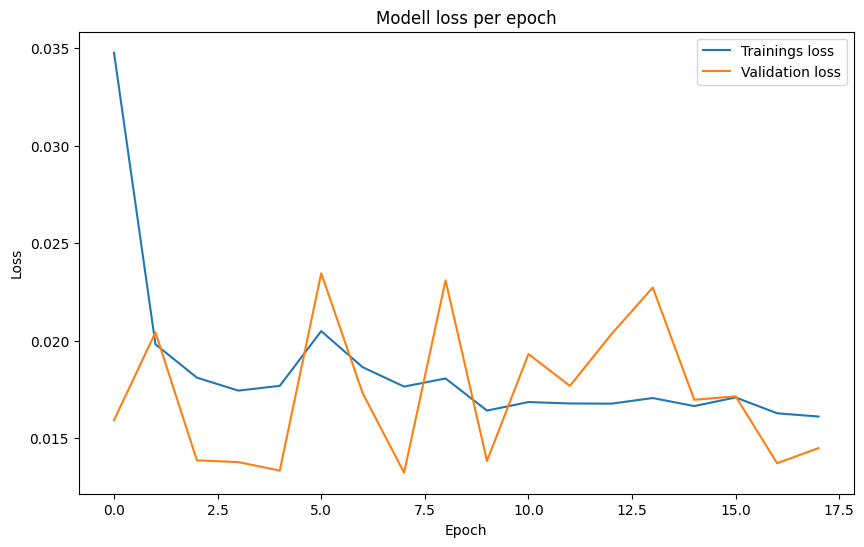

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 111ms/step
R2-Score: 0.3541389958892832


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from keras.models import Sequential
from keras.layers import GRU, LSTM, Conv1D, MaxPooling1D, Dense, Bidirectional, Dropout
import matplotlib.pyplot as plt
import tensorflow as tf
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

# Daten mit Ziel- und exogenen Features
data = extended_df[[target_column_name] + exogenous_features]

# Indizes speichern
indices = data.index

# Daten normalisieren
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Sequenzen erstellen
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:i+seq_length]
        y = data[i+seq_length, 0]  # Zielwert ist die erste Spalte
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 30  # Anzahl der Tage in einer Sequenz
X, y = create_sequences(scaled_data, seq_length)

# Daten in Trainings- und Testsets aufteilen
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Modell erstellen
model = Sequential()

# CNN-Schichten
model.add(Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(seq_length, X_train.shape[2])))
model.add(MaxPooling1D(pool_size=2))
model.add(Dropout(0.2))

# LSTM-Schichten
model.add(Bidirectional(LSTM(units=128, return_sequences=True)))
model.add(Dropout(0.3))
model.add(Bidirectional(LSTM(units=128, return_sequences=True)))
model.add(Dropout(0.3))

# GRU-Schichten
model.add(Bidirectional(GRU(units=128, return_sequences=True)))
model.add(Dropout(0.3))
model.add(Bidirectional(GRU(units=128)))
model.add(Dropout(0.3))

# Dense-Schicht
model.add(Dense(1))

# Modell kompilieren
model.compile(optimizer=Adam(learning_rate=0.001), loss='mean_squared_error')

# Early Stopping Callback
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Modell trainieren
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.2, callbacks=[early_stopping])

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Trainings loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Modell loss per epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Vorhersagen machen
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(np.concatenate((predictions, np.zeros((predictions.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

y_test = scaler.inverse_transform(np.concatenate((y_test.reshape(-1, 1), np.zeros((y_test.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]
y_train = scaler.inverse_transform(np.concatenate((y_train.reshape(-1, 1), np.zeros((y_train.shape[0], scaled_data.shape[1] - 1))), axis=1))[:, 0]

# Indizes wieder hinzufügen
y_test = pd.DataFrame(y_test, index=indices[-len(y_test):])
predictions = pd.DataFrame(predictions, index=indices[-len(predictions):])
y_train = pd.DataFrame(y_train, index=indices[:len(y_train)])

# R2-Score berechnen
r2 = r2_score(y_test, predictions)
print(f'R2-Score: {r2}')


$R^2=0.35$
$MAE=883.55$
$RMSE=1047.17$


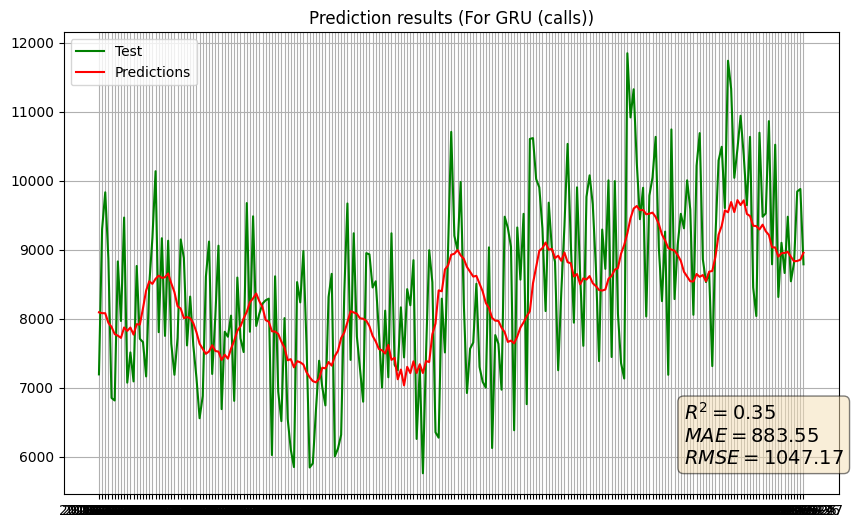

$R^2=-0.02$
$MAE=28.82$
$RMSE=76.93$


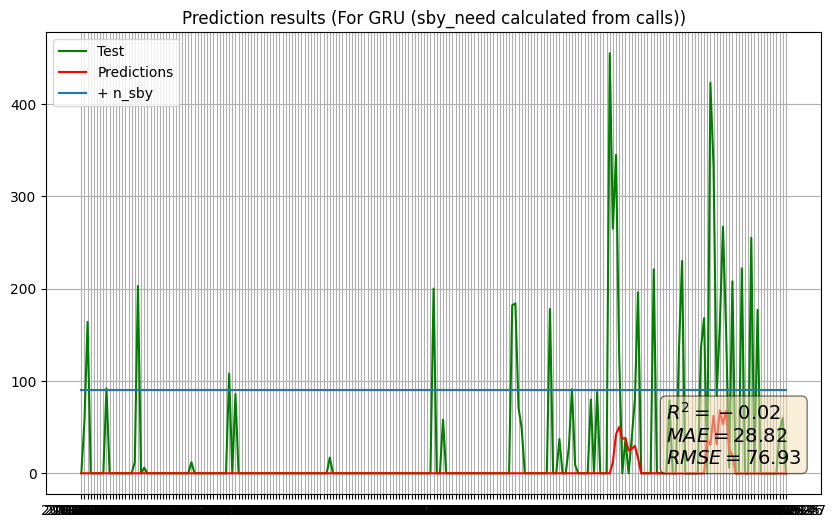

{'Anteil an Tagen mit Unterbesetzung (%)': 21.333333333333336,
 'Anteil an Tagen mit Überbesetzung (%)': 2.2222222222222223,
 'Anteil an Tagen mit perfekter Prediction (%)': 76.44444444444444,
 'Durchschnittliche Überbesetzung': 23.789947525997924,
 'Durchschnittliche Unterbesetzung': 132.59491803291007,
 'Median Überbesetzung': 24.58439441437372,
 'Median Unterbesetzung': 91.87535736408654}

In [ ]:

result_df = extended_df.loc[y_test.index, ["n_duty", "sby_need", "n_sby", "needed_personal"]]

# Values below 0 will be set 0
predictions[predictions < 0] = 0

if target_column_name == "sby_need":

    result_df["sby_need_calc"] = predictions
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))
    plot_regression_predictions(y_test, predictions, additional_column_df=result_df[["n_sby"]], annotation="For GRU")

if target_column_name == "calls":
    result_df["predicted_calls"] = predictions
    result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.7) - row.n_duty) , axis=1)

    plot_regression_predictions(y_test, predictions, annotation="For GRU (calls)")

    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]], annotation="For GRU (sby_need calculated from calls)")
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

if target_column_name == "needed_personal":
    result_df["predicted_needed_personal"] = predictions

    display(calculate_custom_personal_metrics(result_df, "needed_personal", "predicted_needed_personal"))

    plot_regression_predictions(y_test, predictions, annotation="For GRU (needed_personal)")

